# Type Hinting & Static Typing

Python is **dynamically typed**: a variable can hold any type, and Python checks types only when the code runs. **Type hints** add the expected types to the code. Python ignores them at runtime, but tools such as **mypy**, **pyright** and your editor use them to find bugs before the code runs.

**After this lesson you can:**

1. Annotate variables, parameters and return values.
2. Use `list[int]`, `dict[str, float]`, `X | None`, `Literal`, `Callable`.
3. Use `TypedDict`, `Protocol` and generics (the Python 3.12 syntax).
4. Run mypy and read its errors.

## 1. Basic Annotations

```python
def mean(values: list[float]) -> float: ...
count: int = 0
```

| Hint | Meaning |
| :--- | :--- |
| `int`, `str`, `float`, `bool` | basic types |
| `list[int]`, `dict[str, float]`, `tuple[int, str]`, `set[str]` | collections with element types |
| `int \| None` | an `int` or `None` (older form: `Optional[int]`) |
| `Literal["r", "w"]` | only these exact values |
| `Callable[[int], str]` | a function that takes an `int` and returns a `str` |
| `Any` | turn off checking for this value |

In [1]:
from typing import Callable, Literal

def mean(values: list[float]) -> float:
    return sum(values) / len(values)

def find_user(users: dict[int, str], user_id: int) -> str | None:
    return users.get(user_id)

def apply(fn: Callable[[float], float], values: list[float]) -> list[float]:
    return [fn(v) for v in values]

def open_mode(mode: Literal["read", "write"]) -> str:
    return {"read": "r", "write": "w"}[mode]

print(mean([1.0, 2.5, 4.0]), find_user({1: "Ada"}, 2), apply(abs, [-1.5, 2.0]), open_mode("write"))
print("annotations:", mean.__annotations__)

print("hints are not enforced at runtime:", mean([True, False, True]))

2.5 None [1.5, 2.0] w
annotations: {'values': list[float], 'return': <class 'float'>}
hints are not enforced at runtime: 0.6666666666666666


The last line passes booleans to a function that expects floats. Python runs it without complaint. A type checker would report it. This is the key point: **hints document intent; a checker enforces it before runtime**.

## 2. Structured Types: `TypedDict` and `Protocol`

- `TypedDict` describes the keys and value types of a dict, for example a JSON record.
- `Protocol` describes the methods that an object must have, without inheritance (**structural typing**, also called duck typing with a check).

In [2]:
from typing import Protocol, TypedDict

class Movie(TypedDict):
    title: str
    year: int
    rating: float

def describe(m: Movie) -> str:
    return f"{m['title']} ({m['year']}): {m['rating']}/10"

class SupportsPredict(Protocol):
    def predict(self, x: list[float]) -> list[float]: ...

class Doubler:                          # no inheritance from SupportsPredict
    def predict(self, x: list[float]) -> list[float]:
        return [2 * v for v in x]

def evaluate(model: SupportsPredict, x: list[float]) -> float:
    return sum(model.predict(x))

print(describe({"title": "Inception", "year": 2010, "rating": 8.8}))
print(evaluate(Doubler(), [1, 2, 3]))

Inception (2010): 8.8/10
12


## 3. Generics with the Python 3.12 Syntax

A **generic** function or class works with any type and keeps the relation between types. Python 3.12 added a short syntax: the type parameter goes in square brackets after the name (PEP 695). The `type` statement defines a type alias.

In [3]:
def first[T](items: list[T]) -> T:          # T is a type parameter
    return items[0]

class Stack[T]:
    def __init__(self) -> None:
        self._items: list[T] = []

    def push(self, item: T) -> None:
        self._items.append(item)

    def pop(self) -> T:
        return self._items.pop()

type Matrix = list[list[float]]             # type alias (Python 3.12)

def trace(m: Matrix) -> float:
    return sum(m[i][i] for i in range(len(m)))

s: Stack[int] = Stack()
s.push(1); s.push(2)
print(first(["a", "b"]), s.pop(), trace([[1.0, 2.0], [3.0, 4.0]]))

a 2 5.0


## 4. Run a Type Checker

The cell writes a small module with three bugs and runs **mypy** on it. mypy finds all three without running the code.

In [4]:
import subprocess
import sys
import tempfile
import textwrap
from pathlib import Path

src = textwrap.dedent("""
    def mean(values: list[float]) -> float:
        return sum(values) / len(values)

    def find_user(users: dict[int, str], user_id: int) -> str | None:
        return users.get(user_id)

    name = find_user({1: "Ada"}, 1)
    print(name.upper())              # bug 1: name can be None

    result: int = mean([1.0, 2.0])   # bug 2: float assigned to int
    mean("123")                      # bug 3: str is not list[float]
""")
path = Path(tempfile.mkdtemp()) / "buggy.py"
path.write_text(src)
r = subprocess.run([sys.executable, "-m", "mypy", "--strict-optional", "--no-error-summary", "--no-color-output", str(path)],
                   capture_output=True, text=True)
for line in r.stdout.splitlines():
    print(line.replace(str(path.parent) + "/", ""))

/tmp/tmpwdyrc0m2/buggy.py:9: error: Item "None" of "str | None" has no attribute "upper"  [union-attr]
/tmp/tmpwdyrc0m2/buggy.py:11: error: Incompatible types in assignment (expression has type "float", variable has type "int")  [assignment]
/tmp/tmpwdyrc0m2/buggy.py:12: error: Argument 1 to "mean" has incompatible type "str"; expected "list[float]"  [arg-type]


## 5. Do Type Hints Cost Anything at Runtime?

Annotations are stored once, when Python defines the function. They do not run on each call. The experiment calls an annotated and an unannotated function one million times.

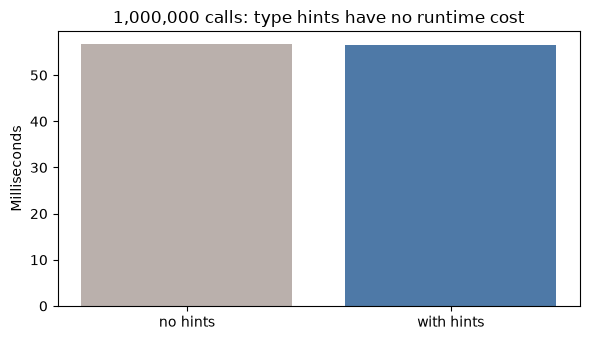

no hints: 56.7 ms | with hints: 56.5 ms | difference: -0.3%


In [5]:
import timeit

import matplotlib.pyplot as plt

def add_plain(a, b):
    return a + b

def add_typed(a: int, b: int) -> int:
    return a + b

t_plain = min(timeit.repeat(lambda: add_plain(3, 4), number=1_000_000, repeat=5))
t_typed = min(timeit.repeat(lambda: add_typed(3, 4), number=1_000_000, repeat=5))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["no hints", "with hints"], [t_plain * 1000, t_typed * 1000], color=["#BAB0AC", "#4E79A7"])
ax.set(title="1,000,000 calls: type hints have no runtime cost", ylabel="Milliseconds")
plt.tight_layout()
plt.show()
print(f"no hints: {t_plain * 1000:.1f} ms | with hints: {t_typed * 1000:.1f} ms | difference: {(t_typed / t_plain - 1):+.1%}")

The difference is only measurement noise: type hints are free at runtime.

*Insight: Add type hints to function signatures first; they give most of the value for little effort. Run a type checker in CI (M02) so that hints stay correct, and use Pydantic (Lesson 14) where you need checks at runtime.*

## Real-World Use Case or Analogy

Type hints are like **labels on the sockets of an electrical panel**. The electricity does not read the labels, but an electrician sees immediately that a 220 V device must not go into the 12 V socket. A type checker is the inspector who checks every label before the building opens.

Large Python code bases (Instagram, Dropbox, most open-source libraries) use type hints and checkers to keep millions of lines maintainable. Modern frameworks also read hints at runtime: FastAPI and Pydantic build validation from them, and LLM tool frameworks build the tool schema from the hints of your function (M29).